In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0,NaN,NaN,NaN,NaN,single
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0,NaN,NaN,NaN,NaN,single
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0,NaN,NaN,NaN,NaN,single


In [2]:
prec_types = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+', '[M+NH4]+']
nist_spectra_df = nist_spectra_df[nist_spectra_df['prec_type'].isin(prec_types)]
print(nist_spectra_df['prec_type'].value_counts())

prec_type
[M+H]+      375648
[M-H]-      161862
[M+Na]+      49023
[M+NH4]+     15556
[M+K]+        6113
Name: count, dtype: int64


In [3]:
ace_max = 50
nce_max = 70
print(f"ACE max: {ace_max}, NCE max: {nce_max}")
print(f"Before filtering: {len(nist_spectra_df)} spectra")
nist_spectra_df = nist_spectra_df[(nist_spectra_df['ace'] <= ace_max) | (nist_spectra_df['nce'] <= nce_max)]
print(f"After filtering: {len(nist_spectra_df)} spectra")
print(nist_spectra_df['prec_type'].value_counts())
nist_spectra_df.loc[:, 'ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500 if pd.isnull(x['ace']) else x['ace'] , 0), axis=1)
nist_spectra_df.loc[:, 'nce'] = nist_spectra_df.apply(lambda x: round(x['ace'] * 500 / x['prec_mz'] if pd.isnull(x['nce']) else x['nce'] , 0), axis=1)

ACE max: 50, NCE max: 70
Before filtering: 608202 spectra
After filtering: 451156 spectra
prec_type
[M+H]+      276955
[M-H]-      121364
[M+Na]+      38580
[M+NH4]+      9948
[M+K]+        4309
Name: count, dtype: int64


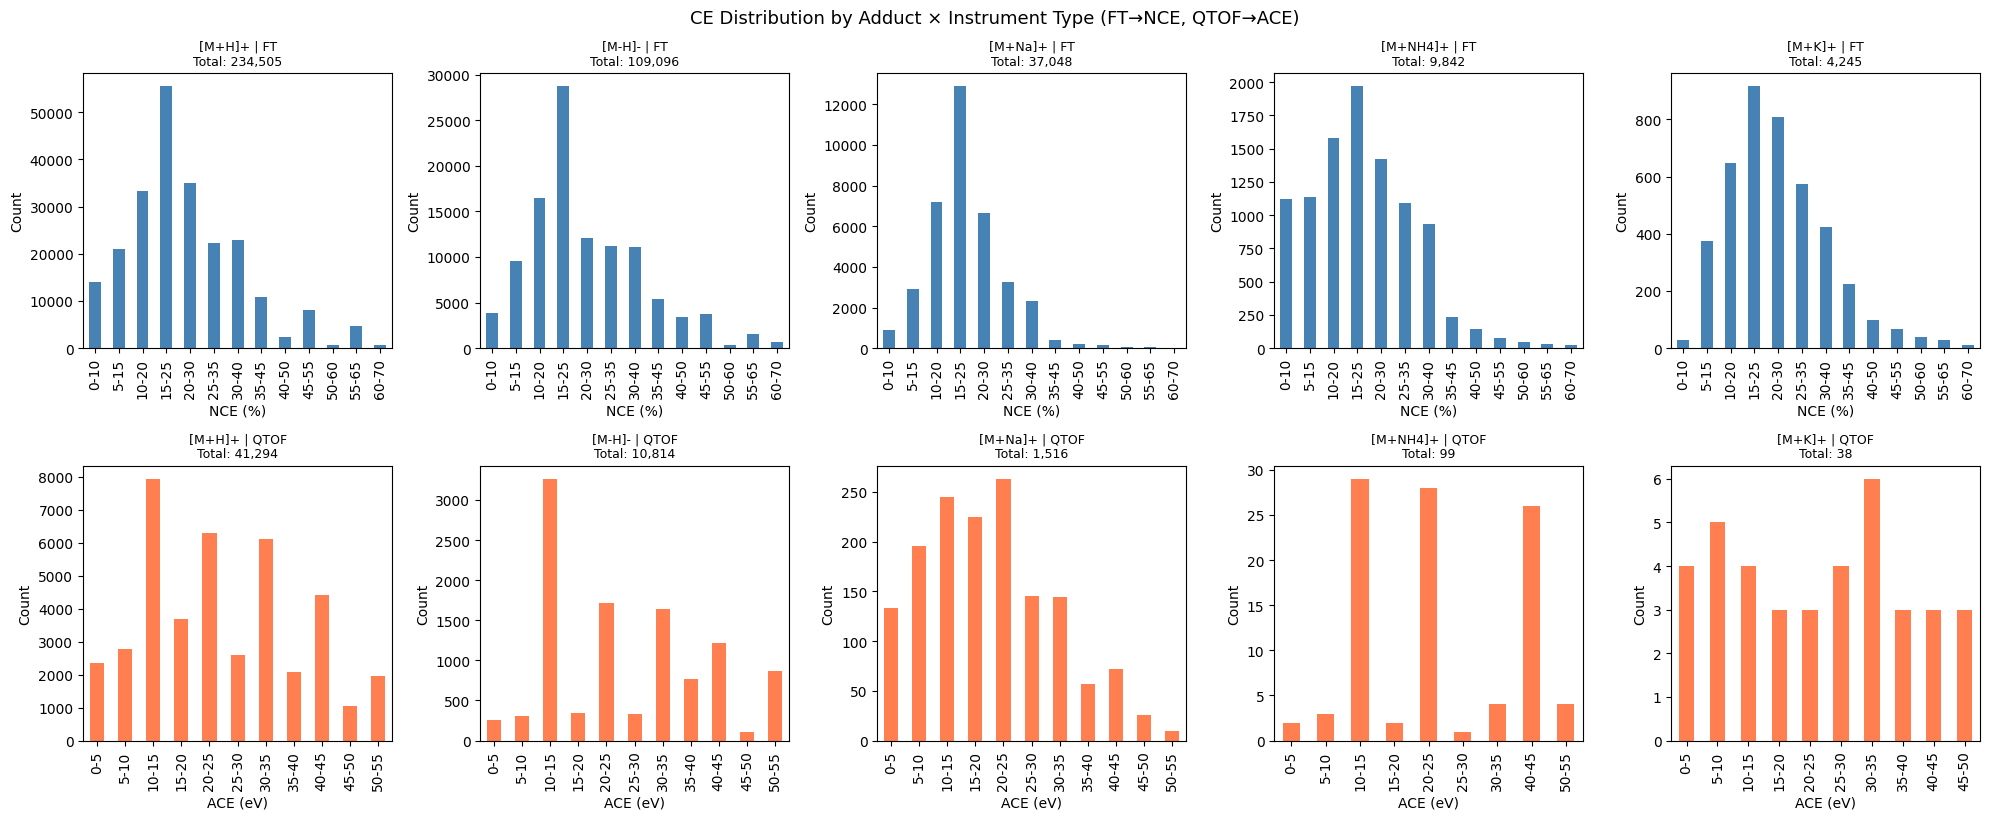

In [4]:
# CE distribution per adduct × instrument type: FT (row 1) → NCE, QTOF (row 2) → ACE
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 70, 5)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
colors = {'FT': 'steelblue', 'QTOF': 'coral'}

combo_counts = (
    nist_spectra_df
    .groupby(['prec_type', 'inst_type'])
    .size()
    .sort_values(ascending=False)
)

ft_combos   = [(pt, it) for pt, it in combo_counts.index if it == 'FT']
qtof_combos = [(pt, it) for pt, it in combo_counts.index if it == 'QTOF']
ncols = max(len(ft_combos), len(qtof_combos), 1)

fig, axes = plt.subplots(2, ncols, figsize=(ncols * 4, 8), sharey=False)

for row, (inst_type, combos) in enumerate([('FT', ft_combos), ('QTOF', qtof_combos)]):
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    bins = list(bin_starts)
    bin_labels = [f"{b}-{b + bin_size}" for b in bins[:-1]]

    for col, (prec_type, _) in enumerate(combos):
        ce_vals = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            ce_col,
        ].dropna()

        binned_data = {lbl: 0 for lbl in bin_labels}
        for val in ce_vals:
            idx = int((val - bins[0]) // bin_size)
            if 0 <= idx < len(bin_labels):
                binned_data[bin_labels[idx]] += 1

        binned_series = pd.Series(binned_data)
        binned_series = binned_series[binned_series > 0]

        ax = axes[row, col]
        if len(binned_series) > 0:
            binned_series.plot(kind='bar', ax=ax, color=colors[inst_type])
        ax.set_title(f"{prec_type} | {inst_type}\nTotal: {len(ce_vals):,}", fontsize=9)
        ax.set_xlabel(ce_label)
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=90)

    for col in range(len(combos), ncols):
        axes[row, col].set_visible(False)

plt.tight_layout()
plt.suptitle('CE Distribution by Adduct × Instrument Type (FT→NCE, QTOF→ACE)', fontsize=13, y=1.02)
plt.show()


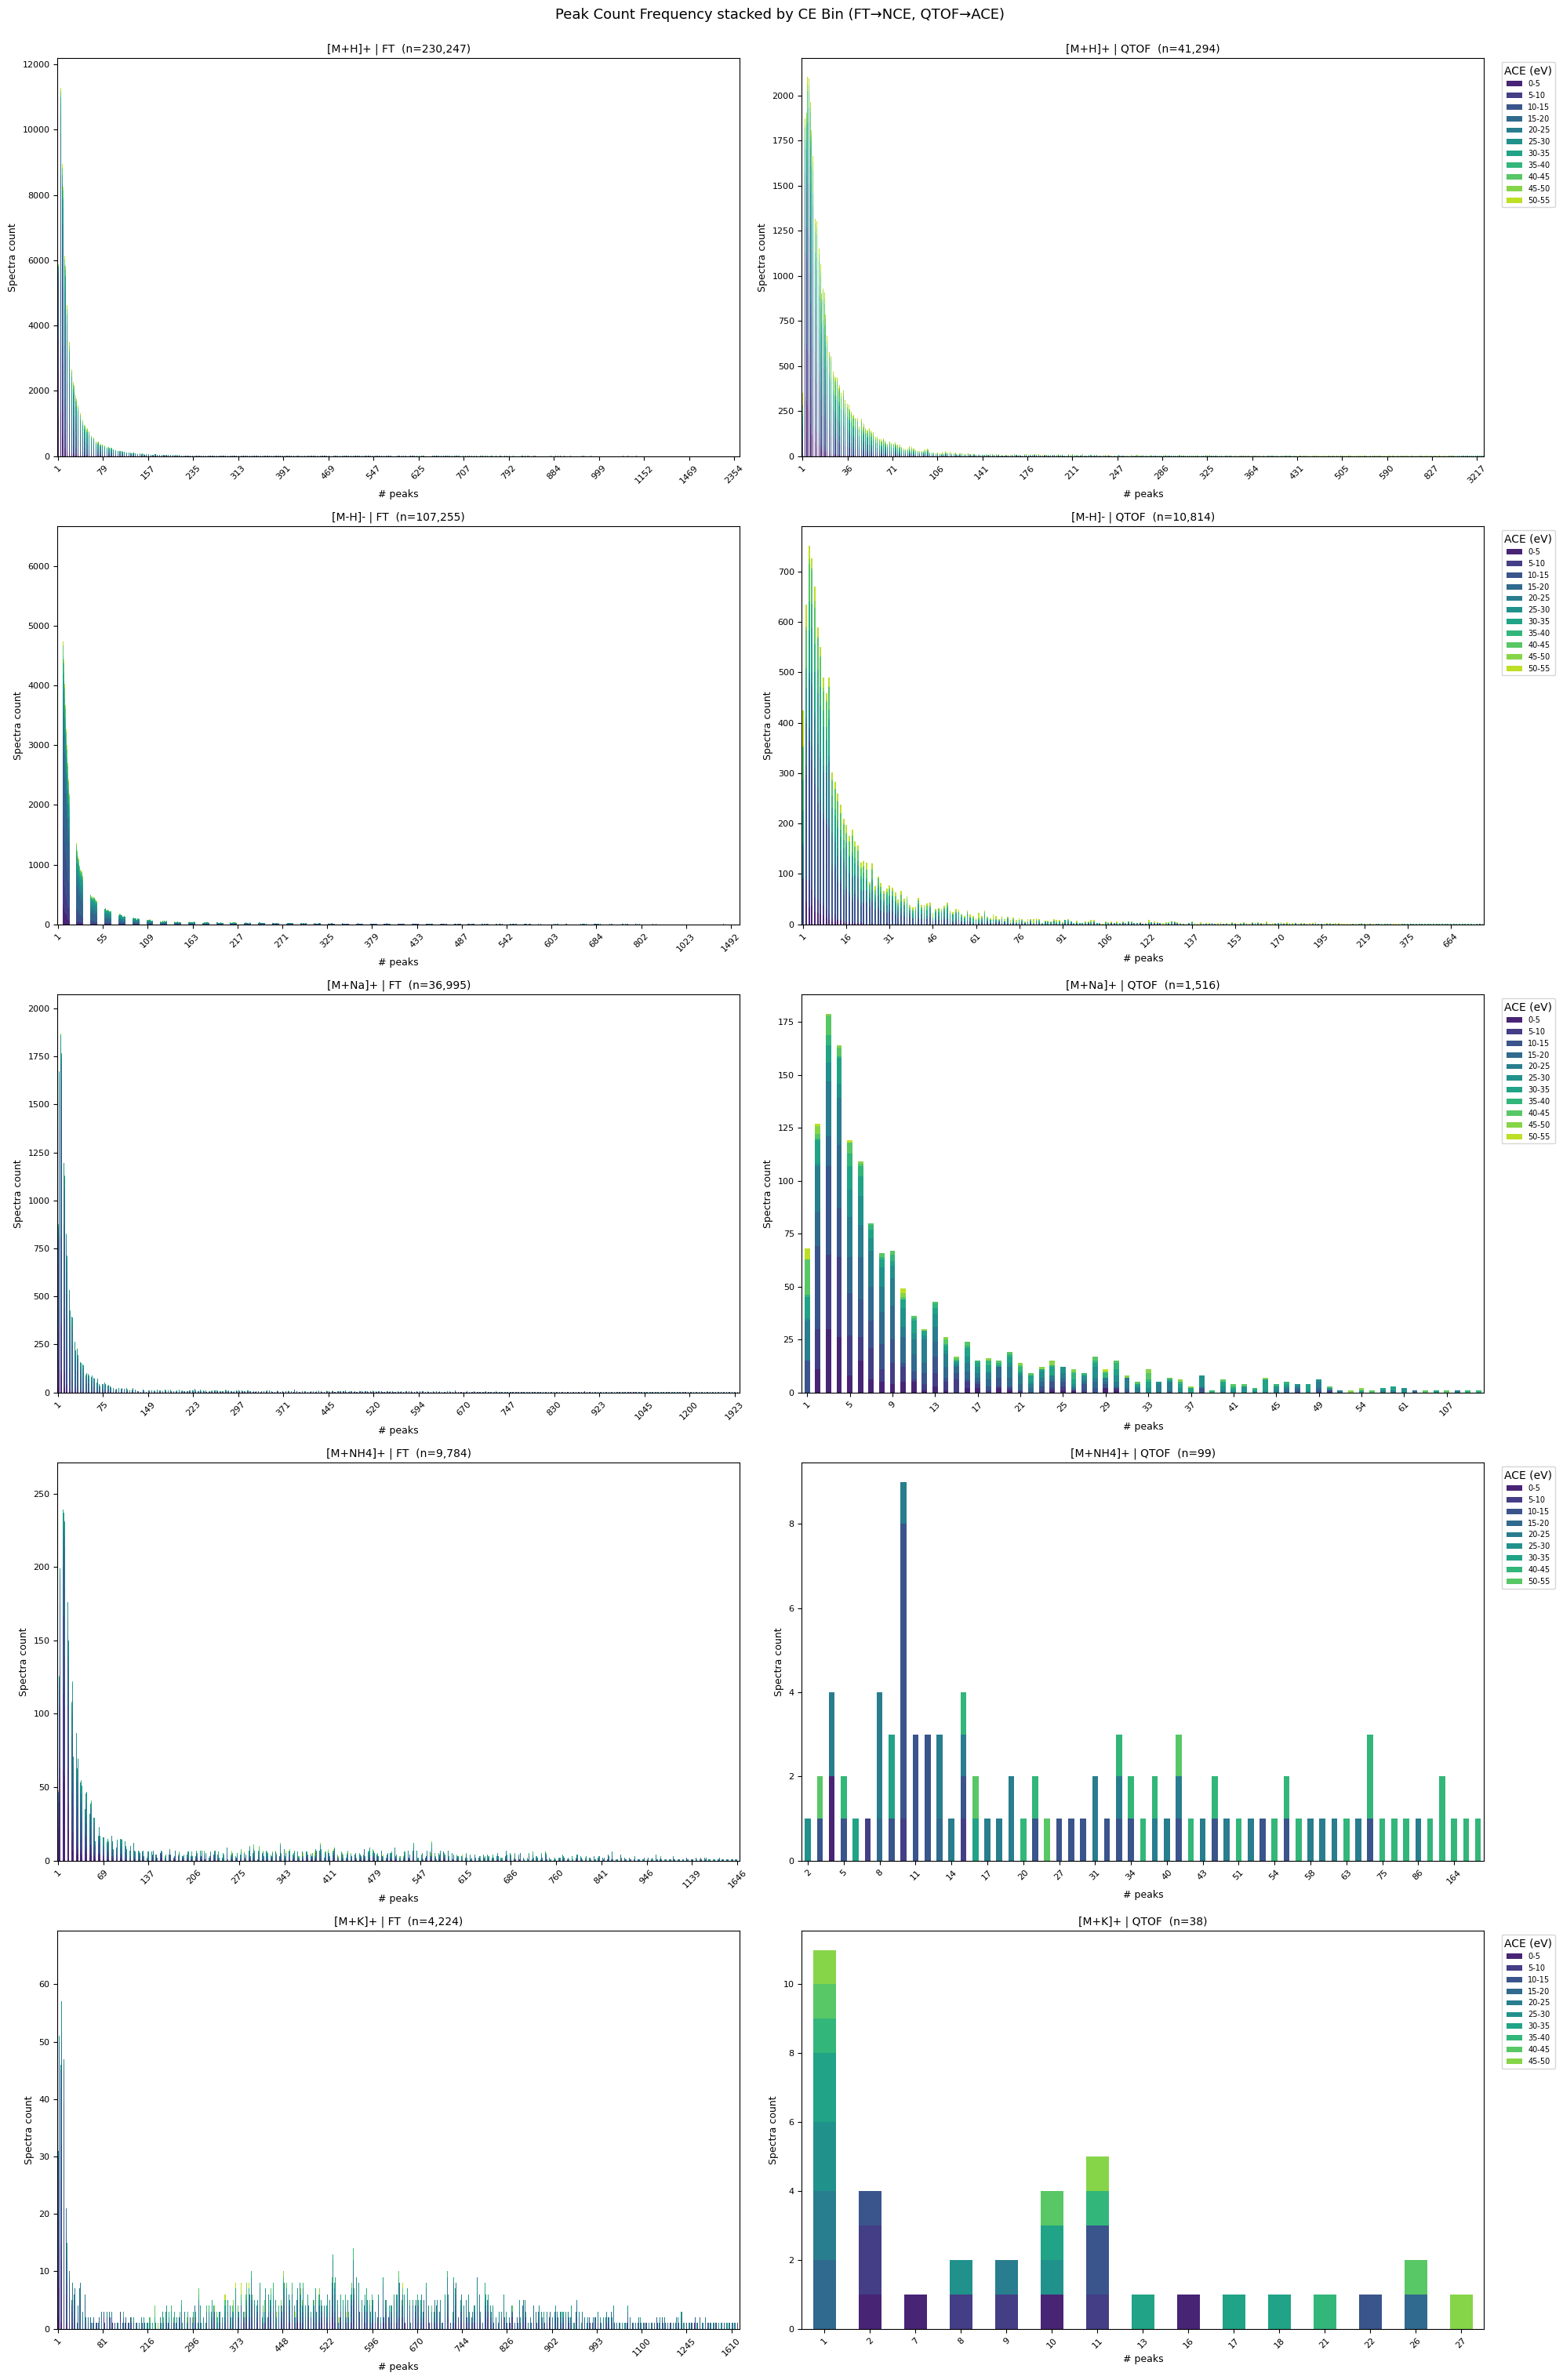

In [5]:
# Peak count frequency: x=raw peak count, stacked by CE bins — FT (row 1) / QTOF (row 2)
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}

if 'num_peaks' not in nist_spectra_df.columns:
    nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(len)

combo_counts = (
    nist_spectra_df
    .groupby(['prec_type', 'inst_type'])
    .size()
    .sort_values(ascending=False)
)
ft_combos   = [(pt, it) for pt, it in combo_counts.index if it == 'FT']
qtof_combos = [(pt, it) for pt, it in combo_counts.index if it == 'QTOF']
nrows = max(len(ft_combos), len(qtof_combos), 1)

fig, axes = plt.subplots(nrows, 2, figsize=(20, 6 * nrows), sharey=False, squeeze=False)

for col, (inst_type, combos) in enumerate([('FT', ft_combos), ('QTOF', qtof_combos)]):
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b + bin_size}" for b in ce_bins[:-1]]
    ce_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(ce_bin_labels)))

    for row, (prec_type, _) in enumerate(combos):
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'num_peaks'],
        ].dropna(subset=[ce_col]).copy()

        df_sub['ce_bin'] = df_sub[ce_col].apply(
            lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
            if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
        )
        df_sub = df_sub.dropna(subset=['ce_bin'])

        # x = raw num_peaks, stacked = ce_bin
        active_ce = [l for l in ce_bin_labels if (df_sub['ce_bin'] == l).any()]
        pivot = (
            df_sub.groupby(['num_peaks', 'ce_bin'])
            .size()
            .unstack(fill_value=0)
            .reindex(columns=active_ce, fill_value=0)
            .sort_index()
        )

        ax = axes[row, col]
        if len(pivot) > 0:
            pivot.plot(kind='bar', stacked=True, ax=ax,
                       color=ce_colors[:len(active_ce)], legend=(col == 1))
        if col == 1:
            ax.legend(title=ce_label, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7)
        ax.set_title(f"{prec_type} | {inst_type}  (n={len(df_sub):,})", fontsize=10)
        ax.set_xlabel('# peaks', fontsize=9)
        ax.set_ylabel('Spectra count', fontsize=9)
        if len(pivot) > 20:
            step = max(1, len(pivot) // 15)
            ax.set_xticks(range(0, len(pivot), step))
            ax.set_xticklabels(pivot.index[::step])
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.tick_params(axis='y', labelsize=8)

    for row in range(len(combos), nrows):
        axes[row, col].set_visible(False)

plt.tight_layout()
plt.suptitle('Peak Count Frequency stacked by CE Bin (FT→NCE, QTOF→ACE)', fontsize=13, y=1.01)
plt.show()


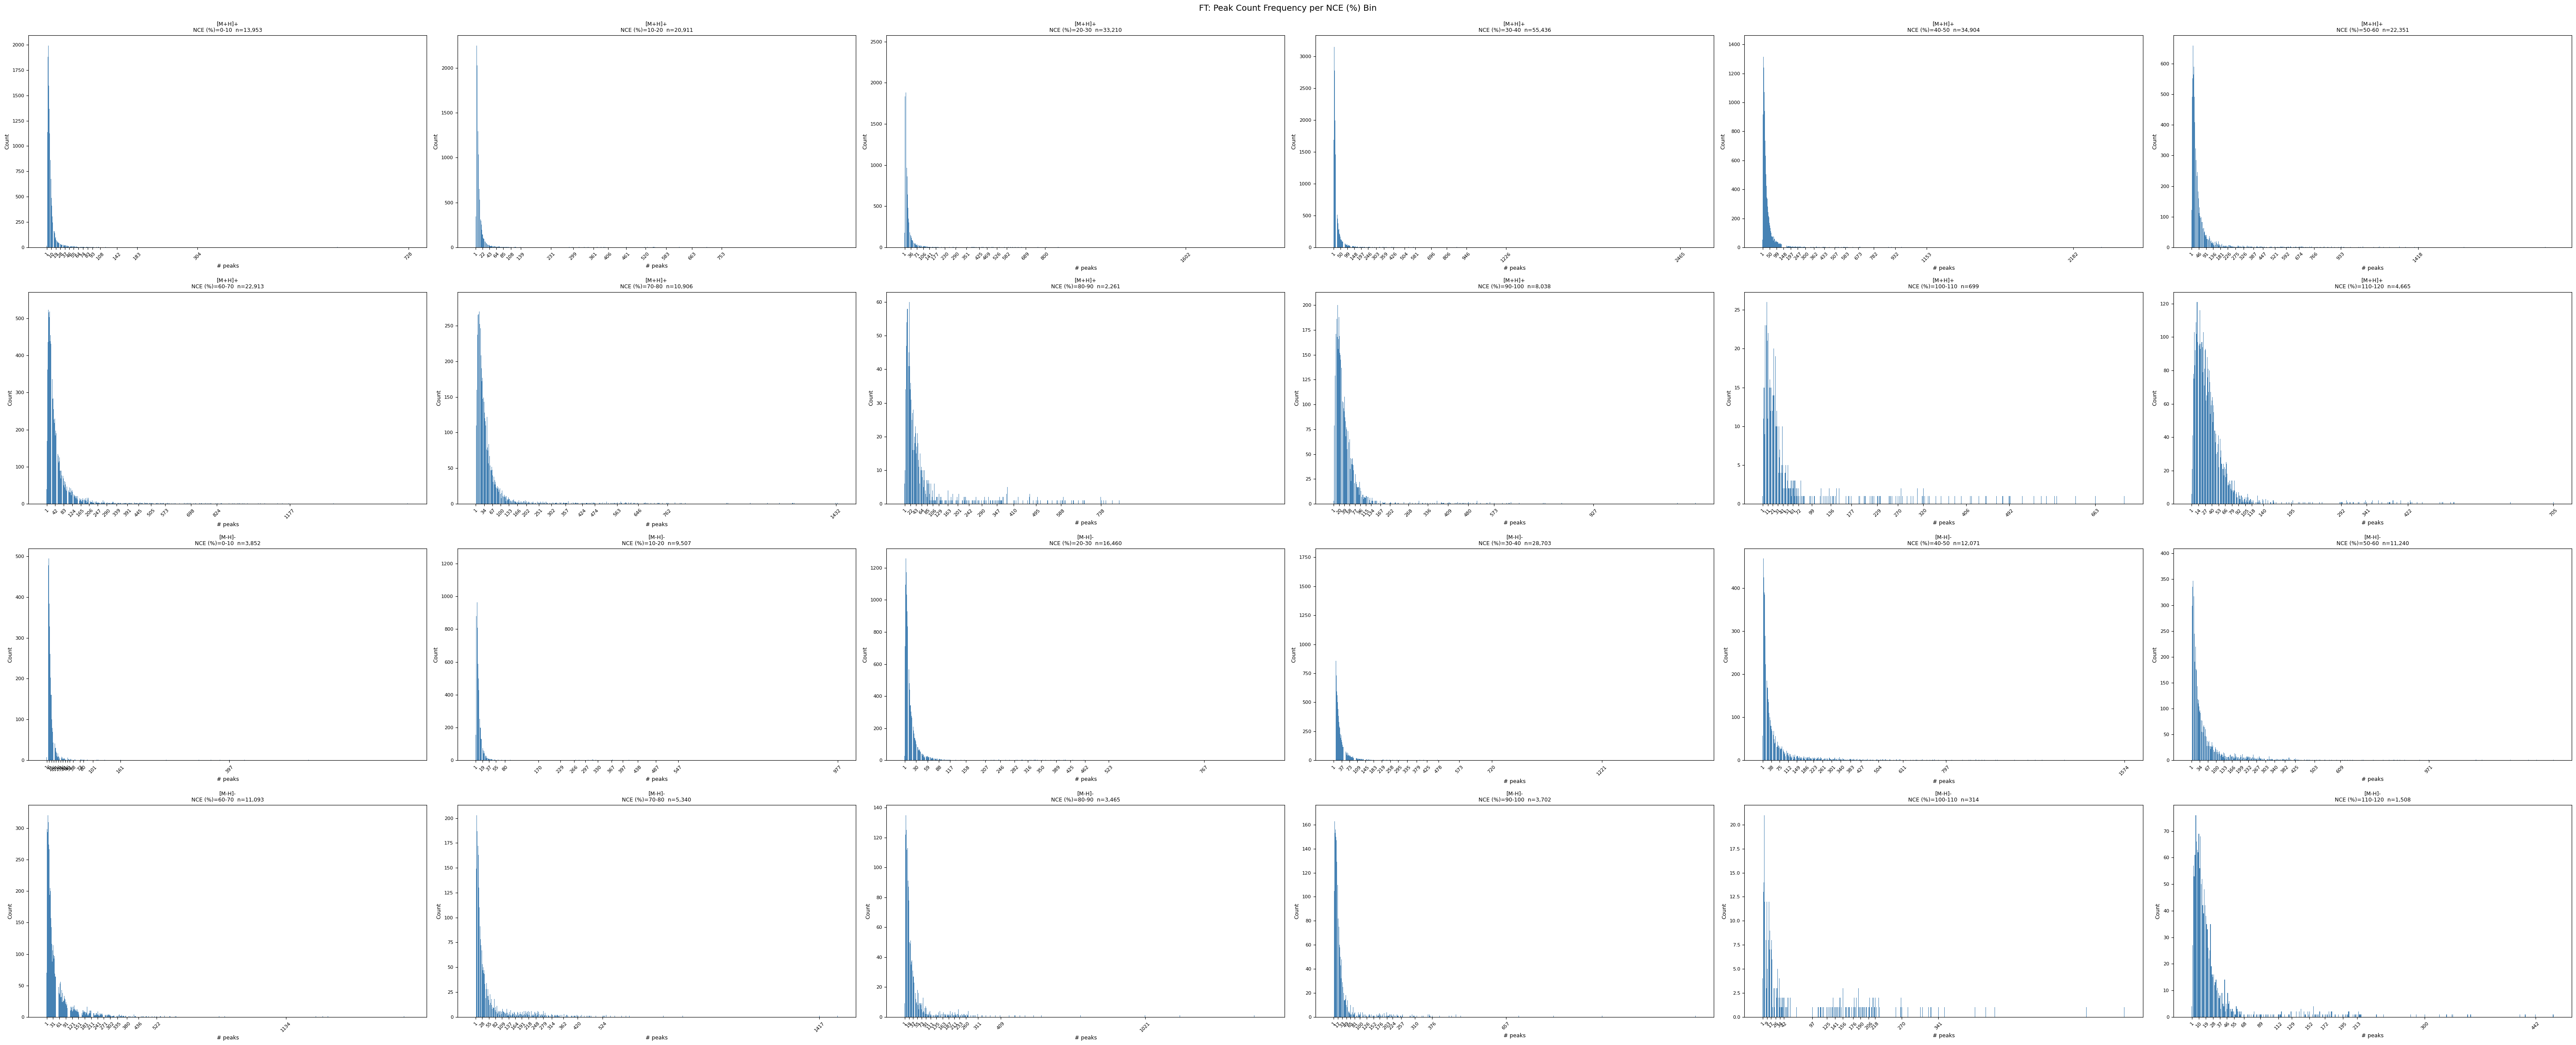

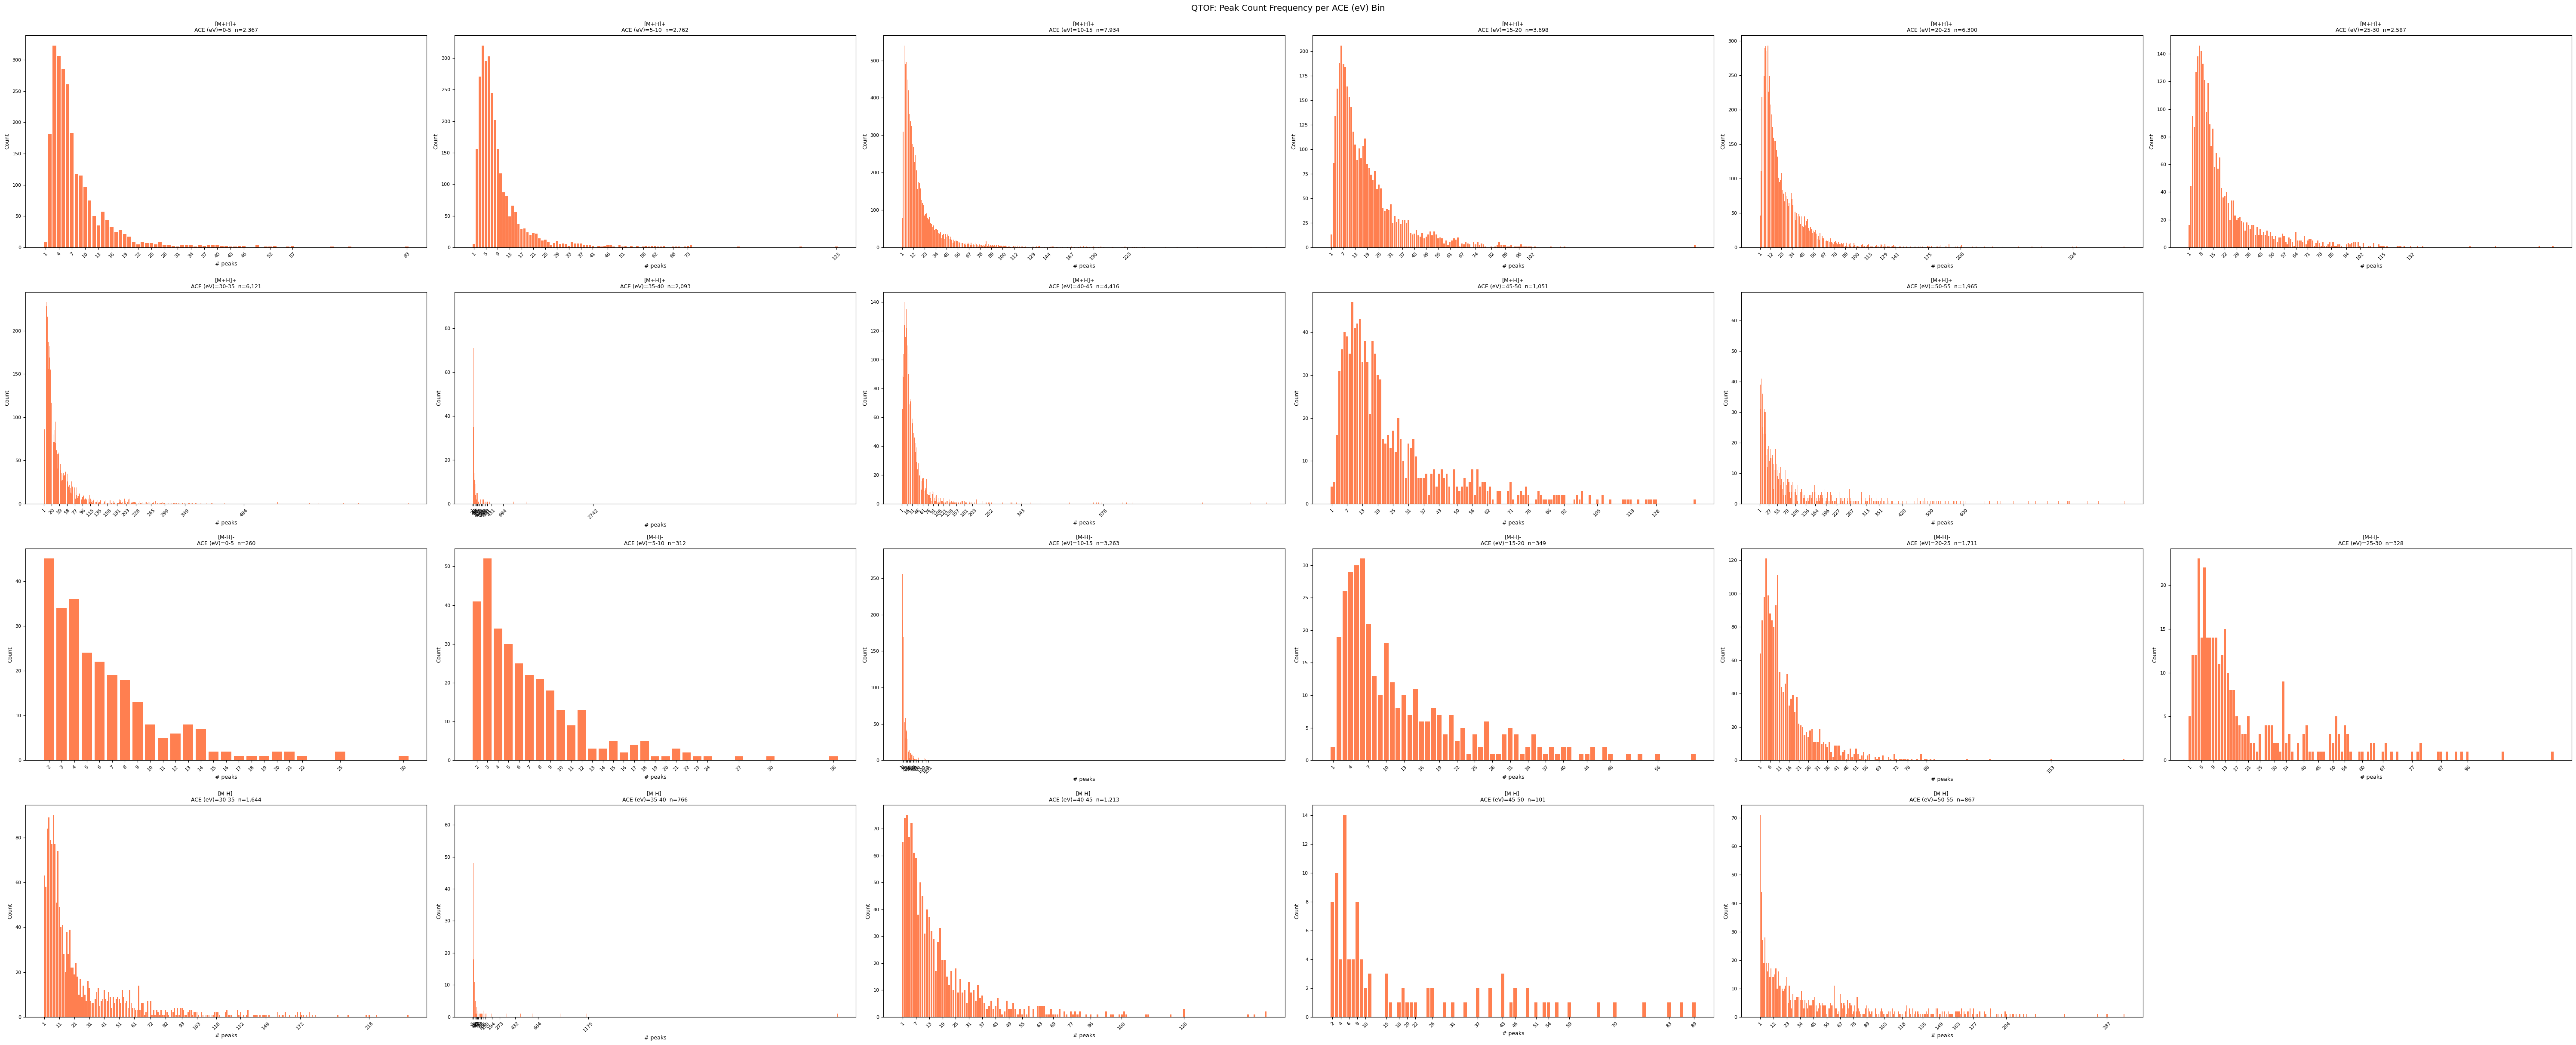

In [6]:
# Peak count frequency per CE bin — raw counts, no binning; FT and QTOF as separate figures
import math

target_adducts = ['[M+H]+', '[M-H]-']
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
colors = {'FT': 'steelblue', 'QTOF': 'coral'}

if 'num_peaks' not in nist_spectra_df.columns:
    nist_spectra_df['num_peaks'] = nist_spectra_df['peaks'].apply(len)

def assign_ce_bin(df_sub, ce_col, bin_size, ce_bins, ce_bin_labels):
    df_sub = df_sub.dropna(subset=[ce_col]).copy()
    df_sub['ce_bin'] = df_sub[ce_col].apply(
        lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
        if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
    )
    return df_sub.dropna(subset=['ce_bin'])

ncols = 6

for inst_type in ['FT', 'QTOF']:
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b + bin_size}" for b in ce_bins[:-1]]

    # Prepare data and active bins per adduct
    adduct_info = []
    for prec_type in target_adducts:
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'num_peaks'],
        ].copy()
        df_sub = assign_ce_bin(df_sub, ce_col, bin_size, ce_bins, ce_bin_labels)
        active_bins = [l for l in ce_bin_labels if (df_sub['ce_bin'] == l).any()]
        adduct_info.append((prec_type, active_bins, df_sub))

    # Compute grid size: each adduct occupies ceil(n_bins / ncols) rows
    adduct_row_offsets = []
    total_rows = 0
    for _, active_bins, _ in adduct_info:
        adduct_row_offsets.append(total_rows)
        total_rows += max(1, math.ceil(len(active_bins) / ncols))

    fig, axes = plt.subplots(total_rows, ncols, figsize=(ncols * 10, total_rows * 6), squeeze=False)

    for (prec_type, active_bins, df_sub), row_offset in zip(adduct_info, adduct_row_offsets):
        for i, ce_bin_lbl in enumerate(active_bins):
            row = row_offset + i // ncols
            col = i % ncols
            freq = (
                df_sub.loc[df_sub['ce_bin'] == ce_bin_lbl, 'num_peaks']
                .value_counts()
                .sort_index()
            )
            ax = axes[row, col]
            ax.bar(freq.index, freq.values, color=colors[inst_type], width=0.8)
            ax.set_title(f"{prec_type}\n{ce_label}={ce_bin_lbl}  n={freq.sum():,}", fontsize=9)
            ax.set_xlabel('# peaks', fontsize=9)
            ax.set_ylabel('Count', fontsize=9)
            # Thin out x ticks if many unique values
            if len(freq) > 20:
                step = max(1, len(freq) // 15)
                ticks = freq.index[::step]
                ax.set_xticks(ticks)
            ax.tick_params(axis='x', rotation=45, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)

        # Hide unused axes in this adduct's rows
        n_rows_used = max(1, math.ceil(len(active_bins) / ncols))
        for i in range(len(active_bins), n_rows_used * ncols):
            axes[row_offset + i // ncols, i % ncols].set_visible(False)

    plt.tight_layout()
    plt.suptitle(f'{inst_type}: Peak Count Frequency per {ce_label} Bin', fontsize=14, y=1.01)
    plt.show()


In [7]:

# Filtered peak count (>1% base peak) — describe by prec_type × inst_type, binned by CE
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}

def filtered_peak_count(peaks):
    if not peaks:
        return 0
    max_int = max(i for _, i in peaks)
    if max_int <= 0:
        return 0
    return sum(1 for _, i in peaks if i > 0.01 * max_int)

nist_spectra_df['filtered_num_peaks'] = nist_spectra_df['peaks'].apply(filtered_peak_count)

target_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+K]+']

records = []
for inst_type, (ce_col, ce_label, bin_size, bin_starts) in inst_ce_cfg.items():
    ce_bins = list(bin_starts)
    ce_bin_labels = [f"{b}-{b+bin_size}" for b in ce_bins[:-1]]

    for prec_type in target_adducts:
        df_sub = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            [ce_col, 'filtered_num_peaks'],
        ].dropna(subset=[ce_col]).copy()

        if len(df_sub) == 0:
            continue

        # Overall row for this adduct × inst combo
        desc = df_sub['filtered_num_peaks'].describe(percentiles=[0.90, 0.95, 0.99])
        records.append({'group': f"{prec_type} | {inst_type} | ALL CE", **desc.to_dict()})

        # Per CE bin
        df_sub['ce_bin'] = df_sub[ce_col].apply(
            lambda v: ce_bin_labels[int((v - ce_bins[0]) // bin_size)]
            if 0 <= int((v - ce_bins[0]) // bin_size) < len(ce_bin_labels) else None
        )
        df_sub = df_sub.dropna(subset=['ce_bin'])

        for lbl in ce_bin_labels:
            subset = df_sub.loc[df_sub['ce_bin'] == lbl, 'filtered_num_peaks']
            if len(subset) < 10:
                continue
            desc = subset.describe(percentiles=[0.90, 0.95, 0.99])
            records.append({'group': f"{prec_type} | {inst_type} | {ce_label}={lbl}", **desc.to_dict()})

summary_df = pd.DataFrame(records).set_index('group')
summary_df[['count', 'mean', 'std', '50%', '90%', '95%', '99%', 'max']].round(1)


,count,mean,std,50%,90%,95%,99%,max
group,,,,,,,,
[M+H]+ | FT | ALL CE,234505.0,16.1,27.0,8.0,36.0,59.0,133.0,957.0
[M+H]+ | FT | NCE (%)=0-10,13953.0,5.5,8.6,4.0,9.0,13.4,36.0,259.0
[M+H]+ | FT | NCE (%)=10-20,20911.0,6.8,13.4,4.0,11.0,18.0,59.0,324.0
[M+H]+ | FT | NCE (%)=20-30,33210.0,10.3,18.4,5.0,20.0,34.0,88.0,957.0
[M+H]+ | FT | NCE (%)=30-40,55436.0,13.3,25.7,6.0,27.0,47.0,117.7,926.0
...,...,...,...,...,...,...,...,...
[M+NH4]+ | QTOF | ALL CE,99.0,27.4,34.4,15.0,55.2,89.4,154.3,219.0
[M+NH4]+ | QTOF | ACE (eV)=10-15,29.0,15.6,13.6,10.0,29.6,38.0,60.0,67.0
[M+NH4]+ | QTOF | ACE (eV)=20-25,28.0,21.1,19.2,14.5,45.9,49.3,76.3,86.0
